# LASV survivor durability — Figure 3 Panels B–D

Focused analysis of confirmed Lassa fever survivors with a known date of discharge (DoDis).

**Panel B:** NP ELISA, GP ELISA, and neutralization versus years since discharge.  
**Panel C:** NP and GPC high-specificity PhIP-Seq peptide breadth versus years since discharge.  
**Panel D:** adjusted time-since-discharge effect estimates with 95% confidence intervals.

All adjusted models include **age and sex** as covariates. The first/baseline sample per survivor is used so each participant contributes once.


In [16]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings('ignore', category=FutureWarning)

# ---------- paths ----------
META_FILE = Path('./metadata_files/master_sample_metadata_111226.csv')
LONG_FILE = Path('./output_files/long_spec_0_98_111226.csv')
OUTDIR = Path('./output_figures/Fig3_DoDis')
OUTDIR.mkdir(parents=True, exist_ok=True)

# ---------- publication style ----------
SURVIVOR_COLOR = '#D55E00'  # Okabe–Ito vermillion
plt.rcParams.update({
    'font.size': 9,
    'axes.labelsize': 10,
    'axes.titlesize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'svg.fonttype': 'none',
    'pdf.fonttype': 42,
})



## 1. Build the survivor DoDis analysis cohort


In [17]:
sample_meta = pd.read_csv(META_FILE)
df = pd.read_csv(LONG_FILE)

sample_meta['collection_date'] = pd.to_datetime(sample_meta['collection_date'], errors='coerce')
sample_meta['discharge_date'] = pd.to_datetime(sample_meta['discharge_date'], errors='coerce')

# Recalculate DoDis from dates as a QC safeguard.
sample_meta['days_since_discharge_calc'] = (
    sample_meta['collection_date'] - sample_meta['discharge_date']
).dt.days
sample_meta['years_since_discharge_calc'] = sample_meta['days_since_discharge_calc'] / 365.25

# Confirmed survivors, known DoDis, first available sample per participant.
survivors = (
    sample_meta.loc[
        (sample_meta['Category'] == 'S') &
        sample_meta['discharge_date'].notna() &
        sample_meta['collection_date'].notna()
    ]
    .sort_values(['participant_id', 'collection_date'])
    .drop_duplicates('participant_id', keep='first')
    .copy()
)

# Use recalculated value so collection/discharge dates are the source of truth.
survivors['years_since_discharge'] = survivors['years_since_discharge_calc']

# Numeric outcomes/covariates.
for col in ['NP_Calc_Conc', 'GP_Calc_Conc', 'Neut_Percent', 'age_years']:
    survivors[col] = pd.to_numeric(survivors[col], errors='coerce')

# Standardize sex labels to a simple categorical variable; inspect before modeling.
survivors['sex_model'] = survivors['sex'].astype('string').str.strip()

print('Survivors with known DoDis:', len(survivors))
print('Years since discharge:', survivors['years_since_discharge'].describe()[['min','25%','50%','75%','max']])
print()
print('Sex:')
print(survivors['sex_model'].value_counts(dropna=False))
print()
print('Age available:', survivors['age_years'].notna().sum())
print('NP ELISA available:', survivors['NP_Calc_Conc'].notna().sum())
print('GP ELISA available:', survivors['GP_Calc_Conc'].notna().sum())
print('Neutralization available:', survivors['Neut_Percent'].notna().sum())



Survivors with known DoDis: 88
Years since discharge: min     0.046543
25%     3.715948
50%     9.092402
75%    15.456537
max    29.475702
Name: years_since_discharge, dtype: float64

Sex:
sex_model
Female    57
Male      31
Name: count, dtype: Int64

Age available: 87
NP ELISA available: 88
GP ELISA available: 88
Neutralization available: 88


/tmp/ipykernel_3304037/3674058505.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sample_meta['collection_date'] = pd.to_datetime(sample_meta['collection_date'], errors='coerce')
/tmp/ipykernel_3304037/3674058505.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sample_meta['discharge_date'] = pd.to_datetime(sample_meta['discharge_date'], errors='coerce')


## 2. Calculate antigen-specific PhIP-Seq breadth


In [18]:
baseline_ids = set(survivors['sample_id'])

lasv = df.loc[
    df['individual'].isin(baseline_ids) &
    df['species'].eq('Mammarenavirus lassaense')
].copy()

# Number of reactive high-specificity peptides per protein.
breadth = (
    lasv.groupby(['individual', 'protein_std'])['reactive']
        .sum()
        .unstack(fill_value=0)
        .reset_index()
        .rename(columns={
            'nucleoprotein': 'NP_breadth',
            'glycoprotein': 'GPC_breadth',
            'polymerase': 'L_breadth',
            'z protein': 'Z_breadth',
        })
)

analysis = survivors.merge(
    breadth,
    left_on='sample_id',
    right_on='individual',
    how='left',
    validate='one_to_one'
)

for col in ['NP_breadth', 'GPC_breadth', 'L_breadth', 'Z_breadth']:
    if col not in analysis.columns:
        analysis[col] = 0
    analysis[col] = analysis[col].fillna(0).astype(int)

print('Analysis N:', len(analysis))
display(analysis[['participant_id','years_since_discharge','NP_Calc_Conc','GP_Calc_Conc','Neut_Percent','NP_breadth','GPC_breadth']].head())



Analysis N: 88


,participant_id,years_since_discharge,NP_Calc_Conc,GP_Calc_Conc,Neut_Percent,NP_breadth,GPC_breadth
0,S-104,8.517454,7.005413,9.730940,72.319247,5,3
1,S-105,2.685832,48.156827,14.049201,83.162489,9,12
2,S-106,2.652977,230.410737,23.987280,86.166650,17,8
3,S-107,4.889802,310.652203,28.565715,95.196260,15,10
4,S-109,0.082136,120.352257,48.354547,83.121249,18,4


## 3. Fit adjusted models

The adjusted models are:

- `log1p(NP ELISA) ~ years since discharge + age + sex`
- `log1p(GP ELISA) ~ years since discharge + age + sex`
- `Neutralization (%) ~ years since discharge + age + sex`
- `NP breadth ~ years since discharge + age + sex` (negative binomial)
- `GPC breadth ~ years since discharge + age + sex` (negative binomial)

The forest plot reports the time effect over **10 years**, which is easier to interpret than a one-year coefficient.


In [19]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.discrete.discrete_model import NegativeBinomial
from statsmodels.stats.multitest import multipletests
import patsy

# statsmodels/patsy does not handle pandas StringDtype reliably
analysis = analysis.copy()

analysis['sex_model'] = analysis['sex_model'].astype(object)

# make sure all modelled numeric variables really are numeric
numeric_cols = [
    'years_since_discharge',
    'age_years',
    'NP_Calc_Conc',
    'GP_Calc_Conc',
    'Neut_Percent',
    'NP_breadth',
    'GPC_breadth'
]

for col in numeric_cols:
    analysis[col] = pd.to_numeric(
        analysis[col],
        errors='coerce'
    )

    
def fit_adjusted_models(data):
    rows = []
    fitted = {}

    specs = [
        ('NP ELISA', 'NP_Calc_Conc', 'ols_log1p'),
        ('GP ELISA', 'GP_Calc_Conc', 'ols_log1p'),
        ('Neutralization', 'Neut_Percent', 'ols'),
        ('NP PhIP breadth', 'NP_breadth', 'neg_bin'),
        ('GPC PhIP breadth', 'GPC_breadth', 'neg_bin'),
    ]

    for label, outcome, model_type in specs:

        cols = [
            outcome,
            'years_since_discharge',
            'age_years',
            'sex_model'
        ]

        tmp = data[cols].dropna().copy()

        # -----------------------------------
        # ELISA: OLS on log1p concentration
        # -----------------------------------
        if model_type == 'ols_log1p':

            tmp['model_outcome'] = np.log1p(tmp[outcome])

            model = smf.ols(
                'model_outcome ~ years_since_discharge '
                '+ age_years + C(sex_model)',
                data=tmp
            ).fit()

        # -----------------------------------
        # Neutralization: ordinary OLS
        # -----------------------------------
        elif model_type == 'ols':

            model = smf.ols(
                f'{outcome} ~ years_since_discharge '
                '+ age_years + C(sex_model)',
                data=tmp
            ).fit()

        # -----------------------------------
        # PhIP breadth: Negative Binomial
        # with dispersion estimated from data
        # -----------------------------------
        elif model_type == 'neg_bin':

            formula = (
                f'{outcome} ~ years_since_discharge '
                '+ age_years + C(sex_model)'
            )

            y, X = patsy.dmatrices(
                formula,
                data=tmp,
                return_type='dataframe'
            )

            model = NegativeBinomial(
                y.iloc[:, 0],
                X
            ).fit(
                disp=False,
                maxiter=1000
            )

        # -----------------------------------
        # Extract time effect
        # -----------------------------------

        beta = model.params['years_since_discharge']

        ci = model.conf_int().loc['years_since_discharge']
        ci_low = ci.iloc[0]
        ci_high = ci.iloc[1]

        p = model.pvalues['years_since_discharge']

        # -----------------------------------
        # Convert to 10-year effect
        # -----------------------------------

        if model_type in ['ols_log1p', 'neg_bin']:

            effect10 = np.exp(beta * 10)
            low10 = np.exp(ci_low * 10)
            high10 = np.exp(ci_high * 10)

            percent_change10 = (
                effect10 - 1
            ) * 100

            if model_type == 'neg_bin':
                effect_type = 'rate ratio per 10 years'
            else:
                effect_type = (
                    'ratio of (ELISA concentration + 1) '
                    'per 10 years'
                )

        else:

            effect10 = beta * 10
            low10 = ci_low * 10
            high10 = ci_high * 10

            percent_change10 = np.nan

            effect_type = (
                'percentage-point change per 10 years'
            )

        rows.append({
            'outcome': label,
            'raw_outcome': outcome,
            'model': model_type,
            'n': len(tmp),

            'beta_per_year': beta,
            'ci_low_per_year': ci_low,
            'ci_high_per_year': ci_high,

            'p_time': p,

            'effect_10y': effect10,
            'effect_10y_low': low10,
            'effect_10y_high': high10,

            'percent_change_10y': percent_change10,

            'effect_type': effect_type
        })

        fitted[label] = model

    # -----------------------------------
    # Multiple-testing correction
    # -----------------------------------

    results = pd.DataFrame(rows)

    results['FDR_time'] = multipletests(
        results['p_time'],
        method='fdr_bh'
    )[1]

    return results, fitted


model_results, fitted_models = fit_adjusted_models(
    analysis
)

display(model_results)

,outcome,raw_outcome,model,n,beta_per_year,ci_low_per_year,ci_high_per_year,p_time,effect_10y,effect_10y_low,effect_10y_high,percent_change_10y,effect_type,FDR_time
0,NP ELISA,NP_Calc_Conc,ols_log1p,87,-0.053780,-0.090092,-0.017469,0.004179,0.584030,0.406198,0.839718,-41.596966,ratio of (ELISA concentration + 1) per 10 years,0.010447
1,GP ELISA,GP_Calc_Conc,ols_log1p,87,-0.030272,-0.059216,-0.001328,0.040592,0.738807,0.553131,0.986811,-26.119336,ratio of (ELISA concentration + 1) per 10 years,0.040592
2,Neutralization,Neut_Percent,ols,87,-0.861947,-1.545450,-0.178443,0.014081,-8.619466,-15.454498,-1.784433,NaN,percentage-point change per 10 years,0.017601
3,NP PhIP breadth,NP_breadth,neg_bin,87,-0.042564,-0.070795,-0.014332,0.003127,0.653353,0.492653,0.866473,-34.664663,rate ratio per 10 years,0.010447
4,GPC PhIP breadth,GPC_breadth,neg_bin,87,-0.045628,-0.080014,-0.011243,0.009301,0.633634,0.449265,0.893663,-36.636631,rate ratio per 10 years,0.015502


In [20]:
for col in ['NP_breadth', 'GPC_breadth']:
    print(
        col,
        'mean =', analysis[col].mean(),
        'variance =', analysis[col].var()
    )

NP_breadth mean = 5.568181818181818 variance = 25.67345872518286
GPC_breadth mean = 3.5454545454545454 variance = 14.158829676071047


## 4. Panel B — humoral waning

Raw observations are shown with a simple linear visual trend and 95% CI. The text annotation reports the **adjusted** time effect from the multivariable model, not the unadjusted correlation.


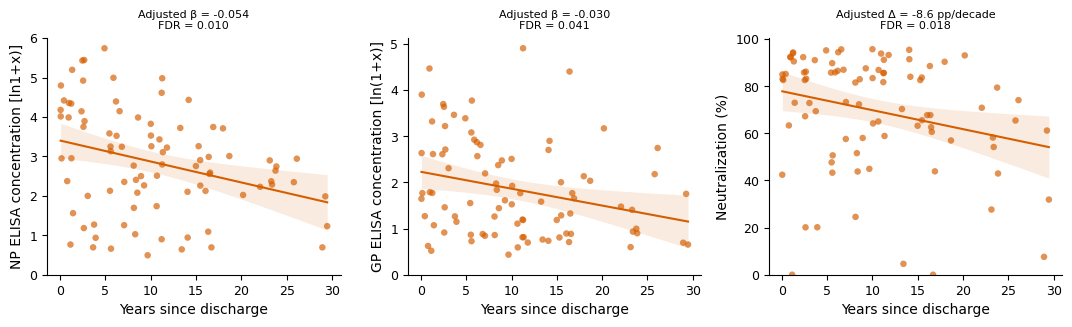

In [36]:
def add_linear_trend(ax, x, y, color=SURVIVOR_COLOR):
    tmp = pd.DataFrame({'x': x, 'y': y}).dropna().sort_values('x')
    if len(tmp) < 4:
        return
    X = sm.add_constant(tmp['x'])
    fit = sm.OLS(tmp['y'], X).fit()
    grid = np.linspace(tmp['x'].min(), tmp['x'].max(), 200)
    pred = fit.get_prediction(sm.add_constant(grid)).summary_frame(alpha=0.05)
    ax.plot(grid, pred['mean'], color=color, lw=1.5)
    ax.fill_between(grid, pred['mean_ci_lower'], pred['mean_ci_upper'], color=color, alpha=0.12, linewidth=0)


def adjusted_annotation(label):
    r = model_results.set_index('outcome').loc[label]

    if label == 'Neutralization':
        return (
            f"Adjusted Δ = {r['effect_10y']:.1f} pp/decade\n"
            f"FDR = {r['FDR_time']:.3f}"
        )

    else:
        return (
            f"Adjusted β = {r['beta_per_year']:.3f}\n"
            f"FDR = {r['FDR_time']:.3f}"
        )

analysis['NP_Calc_Conc_log1p'] = np.log1p(analysis['NP_Calc_Conc'])
analysis['GP_Calc_Conc_log1p'] = np.log1p(analysis['GP_Calc_Conc'])

panel_b_specs = [
    ('NP ELISA', 'NP_Calc_Conc_log1p', 'NP ELISA concentration [ln1+x)]'),
    ('GP ELISA', 'GP_Calc_Conc_log1p', 'GP ELISA concentration [ln(1+x)]'),
    ('Neutralization', 'Neut_Percent', 'Neutralization (%)'),
]

fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.35))

for ax, (label, col, ylabel) in zip(axes, panel_b_specs):
    tmp = analysis[['years_since_discharge', col]].dropna()
    ax.scatter(tmp['years_since_discharge'], tmp[col], s=22, alpha=0.68, color=SURVIVOR_COLOR, edgecolor='none')
    add_linear_trend(ax, tmp['years_since_discharge'], tmp[col])
    ax.set_xlabel('Years since discharge')
    ax.set_ylabel(ylabel)

    ax.set_ylim(bottom=0)
    ax.text(
    0.5, 1.03,
    adjusted_annotation(label),
    transform=ax.transAxes,
    ha='center',
    va='bottom',
    fontsize=8,
    linespacing=1.15
)

fig.tight_layout()
fig.savefig(OUTDIR / 'Fig3B_humoral_waning.svg', bbox_inches='tight')
fig.savefig(OUTDIR / 'Fig3B_humoral_waning.pdf', bbox_inches='tight')
plt.show()



## 5. Panel C — antigen-specific PhIP-Seq breadth waning


In [45]:
def add_adjusted_nb_curve(
    ax,
    data,
    fitted_model,
    color=SURVIVOR_COLOR
):
    # Prediction grid across observed time range
    grid = np.linspace(
        data['years_since_discharge'].min(),
        data['years_since_discharge'].max(),
        200
    )

    # Standardize other covariates
    median_age = data['age_years'].median()
    reference_sex = data['sex_model'].mode().iloc[0]

    pred_df = pd.DataFrame({
        'years_since_discharge': grid,
        'age_years': median_age,
        'sex_model': reference_sex
    })

    # Need design matrix matching the fitted NB model
    formula_rhs = (
        'years_since_discharge + age_years + C(sex_model)'
    )

    X_pred = patsy.dmatrix(
        formula_rhs,
        pred_df,
        return_type='dataframe'
    )

    # Match model columns exactly
    X_pred = X_pred.reindex(
        columns=fitted_model.model.exog_names[:-1],
        fill_value=0
    )

    beta = fitted_model.params.drop('alpha')

    # Predicted mean count
    eta = X_pred @ beta
    mu = np.exp(eta)

    ax.plot(
        grid,
        mu,
        color=color,
        lw=1.5,
        zorder=3
    )

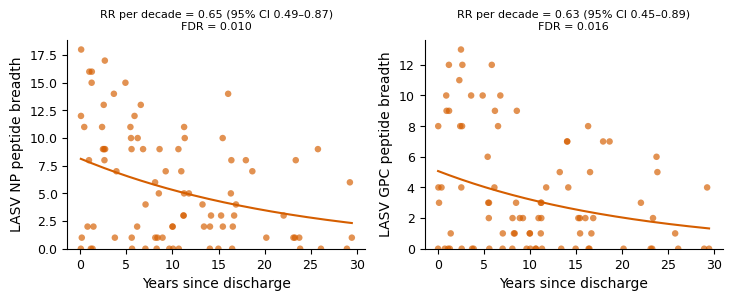

In [46]:
def breadth_annotation(label):
    r = model_results.set_index('outcome').loc[label]

    return (
        f"RR per decade = {r['effect_10y']:.2f} "
        f"(95% CI {r['effect_10y_low']:.2f}–{r['effect_10y_high']:.2f})\n"
        f"FDR = {r['FDR_time']:.3f}"
    )

panel_c_specs = [
    (
        'NP PhIP breadth',
        'NP_breadth',
        'LASV NP peptide breadth'
    ),
    (
        'GPC PhIP breadth',
        'GPC_breadth',
        'LASV GPC peptide breadth'
    ),
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(7.4, 3.3)
)

for ax, (label, col, ylabel) in zip(
    axes,
    panel_c_specs
):

    tmp = analysis[
        [
            'years_since_discharge',
            'age_years',
            'sex_model',
            col
        ]
    ].dropna()

    # Observed data
    ax.scatter(
        tmp['years_since_discharge'],
        tmp[col],
        s=22,
        alpha=0.68,
        color=SURVIVOR_COLOR,
        edgecolor='none',
        zorder=2
    )

    # Adjusted negative-binomial curve
    add_adjusted_nb_curve(
        ax,
        tmp,
        fitted_models[label]
    )

    ax.set_xlabel('Years since discharge')
    ax.set_ylabel(ylabel)

    # Counts cannot be negative
    ax.set_ylim(bottom=0)


    ax.text(
    0.5,
    1.04,
    breadth_annotation(label),
    transform=ax.transAxes,
    ha='center',
    va='bottom',
    fontsize=8
)

fig.tight_layout(rect=[0, 0, 1, 0.94])

plt.show()

## 6. Panel D — adjusted effect-size summary

Because neutralization is modeled on an additive percentage-point scale whereas ELISA and breadth outcomes are naturally shown as multiplicative ratios, Panel D uses **two aligned forest sections** rather than putting incompatible effect measures on one x-axis.


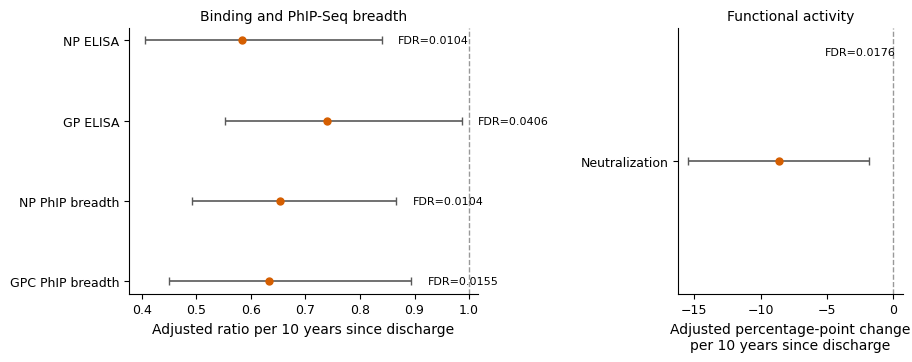

In [23]:
ratio_labels = ['NP ELISA', 'GP ELISA', 'NP PhIP breadth', 'GPC PhIP breadth']
ratio_df = model_results.set_index('outcome').loc[ratio_labels].reset_index()
neut_df = model_results.loc[model_results['outcome'] == 'Neutralization'].copy()

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.7), gridspec_kw={'width_ratios': [1.55, 1]})

# ---- multiplicative outcomes ----
ax = axes[0]
y = np.arange(len(ratio_df))[::-1]
ax.errorbar(
    ratio_df['effect_10y'], y,
    xerr=[ratio_df['effect_10y'] - ratio_df['effect_10y_low'], ratio_df['effect_10y_high'] - ratio_df['effect_10y']],
    fmt='o', color=SURVIVOR_COLOR, ecolor='0.35', elinewidth=1.2, capsize=3, markersize=5
)
ax.axvline(1, color='0.6', ls='--', lw=1)
ax.set_yticks(y)
ax.set_yticklabels(ratio_df['outcome'])
ax.set_xlabel('Adjusted ratio per 10 years since discharge')
ax.set_title('Binding and PhIP-Seq breadth')

for yi, (_, r) in zip(y, ratio_df.iterrows()):
    ax.text(r['effect_10y_high'] + 0.03, yi, f"FDR={r['FDR_time']:.3g}", va='center', fontsize=8)

# ---- neutralization ----
ax = axes[1]
r = neut_df.iloc[0]
ax.errorbar(
    r['effect_10y'], 0,
    xerr=[[r['effect_10y'] - r['effect_10y_low']], [r['effect_10y_high'] - r['effect_10y']]],
    fmt='o', color=SURVIVOR_COLOR, ecolor='0.35', elinewidth=1.2, capsize=3, markersize=5
)
ax.axvline(0, color='0.6', ls='--', lw=1)
ax.set_yticks([0])
ax.set_yticklabels(['Neutralization'])
ax.set_xlabel('Adjusted percentage-point change\nper 10 years since discharge')
ax.set_title('Functional activity')
ax.text(0.97, 0.93, f"FDR={r['FDR_time']:.3g}", transform=ax.transAxes, ha='right', va='top', fontsize=8)

fig.tight_layout(w_pad=2.5)
fig.savefig(OUTDIR / 'Fig3D_adjusted_effect_forest.svg', bbox_inches='tight')
fig.savefig(OUTDIR / 'Fig3D_adjusted_effect_forest.pdf', bbox_inches='tight')
plt.show()



## 7. Publication table and model diagnostics


In [24]:
publication_table = model_results[[
    'outcome', 'n', 'beta_per_year', 'ci_low_per_year', 'ci_high_per_year',
    'p_time', 'FDR_time', 'effect_10y', 'effect_10y_low', 'effect_10y_high', 'effect_type'
]].copy()

publication_table.to_csv(OUTDIR / 'Fig3_adjusted_time_effects.csv', index=False)
display(publication_table)

# Optional model summaries for detailed QC.
for label, model in fitted_models.items():
    print()
    print('='*80)
    print(label)
    print('='*80)
    print(model.summary())



,outcome,n,beta_per_year,ci_low_per_year,ci_high_per_year,p_time,FDR_time,effect_10y,effect_10y_low,effect_10y_high,effect_type
0,NP ELISA,87,-0.053780,-0.090092,-0.017469,0.004179,0.010447,0.584030,0.406198,0.839718,ratio of (ELISA concentration + 1) per 10 years
1,GP ELISA,87,-0.030272,-0.059216,-0.001328,0.040592,0.040592,0.738807,0.553131,0.986811,ratio of (ELISA concentration + 1) per 10 years
2,Neutralization,87,-0.861947,-1.545450,-0.178443,0.014081,0.017601,-8.619466,-15.454498,-1.784433,percentage-point change per 10 years
3,NP PhIP breadth,87,-0.042564,-0.070795,-0.014332,0.003127,0.010447,0.653353,0.492653,0.866473,rate ratio per 10 years
4,GPC PhIP breadth,87,-0.045628,-0.080014,-0.011243,0.009301,0.015502,0.633634,0.449265,0.893663,rate ratio per 10 years



NP ELISA
                            OLS Regression Results                            
Dep. Variable:          model_outcome   R-squared:                       0.112
Model:                            OLS   Adj. R-squared:                  0.080
Method:                 Least Squares   F-statistic:                     3.487
Date:                Thu, 12 Nov 2026   Prob (F-statistic):             0.0193
Time:                        22:28:10   Log-Likelihood:                -141.63
No. Observations:                  87   AIC:                             291.3
Df Residuals:                      83   BIC:                             301.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept           